In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install segmentation_models_pytorch h5py gradio scikit-image

Mounted at /content/drive


In [ ]:
import os, glob, re, json, random
import numpy as np, h5py, torch
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from scipy import ndimage as ndi
from skimage import measure

PH3 = '/content/drive/MyDrive/TerraSeg/phase3'
OUT = '/content/drive/MyDrive/TerraSeg/phase5'
os.makedirs(OUT, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

cfg = json.load(open(f'{PH3}/final_config.json'))
MEAN = np.array(cfg['mean'], np.float32)
STD = np.array(cfg['std'], np.float32)
CHANNEL_NAMES = cfg['channel_order']

# Two models you can demo. 'final' = the one chosen by validation IoU in Phase 3.
# 'baseline' = plain ResNet34 U-Net (it scored the same within noise, so either is honest to show).
CHOICES = {
    'final':    dict(ckpt=f'{PH3}/final_model.pth', attn=cfg['config']['attn'], thr=cfg['threshold'], tta=cfg['tta'], label=cfg['experiment']),
    'baseline': dict(ckpt=f'{PH3}/runs/E0_baseline_s42.pth', attn=None, thr=0.45, tta=False, label='E0_baseline'),
}
CHOICE = 'final'            # change to 'baseline' to demo the plain model
CH = CHOICES[CHOICE]
print("Using:", CH['label'], "| threshold", CH['thr'], "| TTA", CH['tta'])

Device: cuda
Using: E2_scse | threshold 0.40000000000000013 | TTA True


In [ ]:
model = smp.Unet('resnet34', encoder_weights=None, in_channels=14, classes=1,
                 decoder_attention_type=CH['attn']).to(device)
model.load_state_dict(torch.load(CH['ckpt'], map_location=device))
model.eval()
print("Model loaded. Parameters (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 2))

def to_input(raw):
    # raw: (n, 14, 128, 128) in original units  ->  normalised tensor, using TRAINING statistics
    x = (raw - MEAN.reshape(1, 14, 1, 1)) / STD.reshape(1, 14, 1, 1)
    return torch.from_numpy(x.astype(np.float32))

@torch.no_grad()
def predict_probs(x, tta=False):
    model.eval()
    p = torch.sigmoid(model(x))
    if not tta:
        return p
    p = p + torch.sigmoid(model(x.flip(-1))).flip(-1)
    p = p + torch.sigmoid(model(x.flip(-2))).flip(-2)
    p = p + torch.sigmoid(model(x.flip([-1, -2]))).flip([-1, -2])
    return p / 4

Model loaded. Parameters (M): 24.58


In [ ]:
from huggingface_hub import snapshot_download
snapshot_download(repo_id="ibm-nasa-geospatial/Landslide4sense", repo_type="dataset",
                  allow_patterns=["*train*"], local_dir="/content/l4s", max_workers=8)

def num(p): return int(re.findall(r'(\d+)\.h5$', p)[0])
img_files  = sorted(glob.glob('/content/l4s/images/train/image_*.h5'), key=num)
mask_files = sorted(glob.glob('/content/l4s/annotations/train/mask_*.h5'), key=num)
assert len(img_files) == len(mask_files) > 0
def first(h): return h[list(h.keys())[0]][:]

test_idx = np.load(f'{PH3}/split.npz')['test']
Xt_raw = np.zeros((len(test_idx), 14, 128, 128), np.float32)
Yt = np.zeros((len(test_idx), 1, 128, 128), np.float32)
for k, j in enumerate(test_idx):
    with h5py.File(img_files[j]) as h: Xt_raw[k] = np.nan_to_num(first(h)).transpose(2, 0, 1)
    with h5py.File(mask_files[j]) as h: Yt[k, 0] = first(h)
print("test patches:", len(test_idx), "| landslide share:", round(float(Yt.mean()) * 100, 2), "%")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7603 files:   0%|          | 0/7603 [00:00<?, ?it/s]

test patches: 571 | landslide share: 2.21 %


In [ ]:
# 1) what does the saved file say?
print("config mean[0], std[0], mean[13], std[13]:", MEAN[0], STD[0], MEAN[13], STD[13])

# 2) recompute the true statistics from the raw TRAINING patches (same formula as Phase 3)
tr_idx = np.load(f'{PH3}/split.npz')['train']
s1 = np.zeros(14, np.float64); s2 = np.zeros(14, np.float64); cnt = 0
for st in range(0, len(tr_idx), 256):
    ids = tr_idx[st:st + 256]
    chunk = np.zeros((len(ids), 14, 128, 128), np.float32)
    for k, j in enumerate(ids):
        with h5py.File(img_files[j]) as h: chunk[k] = np.nan_to_num(first(h)).transpose(2, 0, 1)
    b = chunk.astype(np.float64)
    s1 += b.sum(axis=(0, 2, 3)); s2 += (b ** 2).sum(axis=(0, 2, 3)); cnt += b.shape[0] * 128 * 128
MEAN_NEW = (s1 / cnt).astype(np.float32)
STD_NEW = (np.sqrt(np.maximum(s2 / cnt - (s1 / cnt) ** 2, 1e-12)) + 1e-6).astype(np.float32)
print("recomputed mean[0], std[0], mean[13], std[13]:", MEAN_NEW[0], STD_NEW[0], MEAN_NEW[13], STD_NEW[13])
MEAN, STD = MEAN_NEW, STD_NEW
# 3) Verify that all 14 channels have valid statistics

assert MEAN.shape == (14,)
assert STD.shape == (14,)
assert np.all(np.isfinite(MEAN))
assert np.all(np.isfinite(STD))
assert np.all(STD > 0)

print("\nNormalization verification successful!")
print("All 14 channels have valid mean and standard deviation.")

# Display all channel statistics
for i in range(14):
    print(f"Channel {i}: mean={MEAN[i]:.6f}, std={STD[i]:.6f}")

config mean[0], std[0], mean[13], std[13]: 1.1145121e-07 0.9999939 4.2237716e-08 1.0000001
recomputed mean[0], std[0], mean[13], std[13]: 0.9260318 0.14138201 1.6463886 1.0743169

Normalization verification successful!
All 14 channels have valid mean and standard deviation.
Channel 0: mean=0.926032, std=0.141382
Channel 1: mean=0.922748, std=0.220936
Channel 2: mean=0.953597, std=0.317671
Channel 3: mean=0.957943, std=0.569697
Channel 4: mean=1.021306, std=0.457069
Channel 5: mean=1.041819, std=0.443463
Channel 6: mean=1.035101, std=0.461850
Channel 7: mean=1.045890, std=0.491598
Channel 8: mean=1.169753, std=0.511860
Channel 9: mean=1.169197, std=0.669243
Channel 10: mean=1.047531, std=0.527689
Channel 11: mean=1.034412, std=0.655917
Channel 12: mean=1.248974, std=0.679045
Channel 13: mean=1.646389, std=1.074317


In [ ]:
def evaluate_test(thr, tta):
    tp = fp = fn = 0.0
    for s in range(0, len(Xt_raw), 32):
        x = to_input(Xt_raw[s:s + 32]).to(device)
        p = (predict_probs(x, tta)[:, 0].cpu().numpy() > thr)
        t = Yt[s:s + 32, 0] > 0.5
        tp += (p & t).sum(); fp += (p & ~t).sum(); fn += (~p & t).sum()
    return dict(IoU=tp / (tp + fp + fn + 1e-9), F1=2 * tp / (2 * tp + fp + fn + 1e-9),
                Precision=tp / (tp + fp + 1e-9), Recall=tp / (tp + fn + 1e-9))

res = evaluate_test(CH['thr'], CH['tta'])
print({k: round(float(v), 4) for k, v in res.items()})

{'IoU': 0.6059, 'F1': 0.7546, 'Precision': 0.7536, 'Recall': 0.7557}


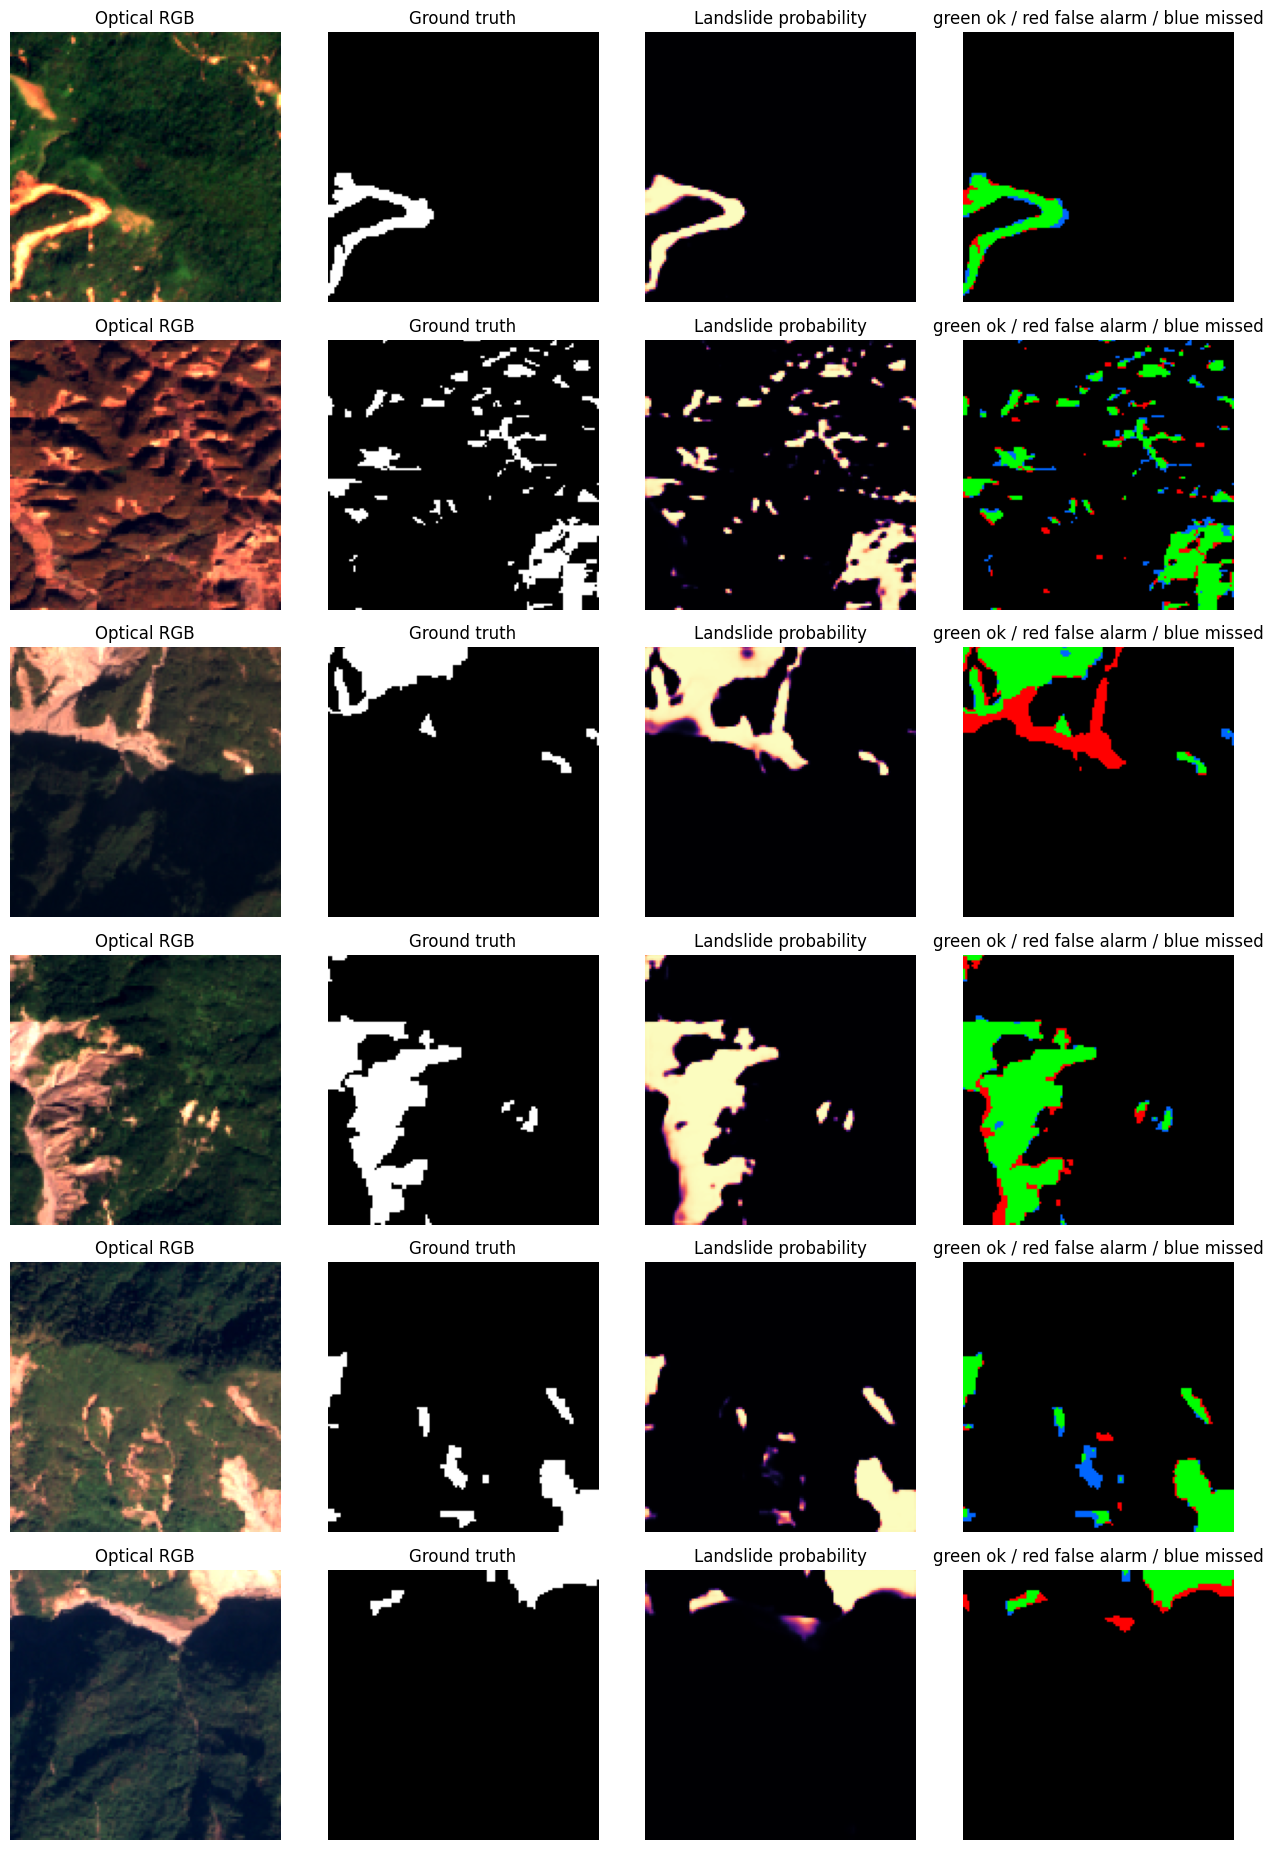

In [ ]:
def rgb_of(raw14):
    rgb = raw14[[3, 2, 1]].transpose(1, 2, 0)                 # B4, B3, B2 = red, green, blue
    lo, hi = np.percentile(rgb, 2), np.percentile(rgb, 98)
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

def err_map(pred, gt):
    img = np.zeros(pred.shape + (3,), np.float32)
    img[pred & gt] = (0, 1, 0); img[pred & ~gt] = (1, 0, 0); img[~pred & gt] = (0, 0.4, 1)
    return img

sel = [i for i in range(len(Xt_raw)) if Yt[i].sum() >= 300][:6]
probs = predict_probs(to_input(Xt_raw[sel]).to(device), CH['tta'])[:, 0].cpu().numpy()

fig, ax = plt.subplots(len(sel), 4, figsize=(13, 3.1 * len(sel)))
for r, i in enumerate(sel):
    ax[r, 0].imshow(rgb_of(Xt_raw[i])); ax[r, 0].set_title("Optical RGB")
    ax[r, 1].imshow(Yt[i, 0], cmap='gray'); ax[r, 1].set_title("Ground truth")
    ax[r, 2].imshow(probs[r], cmap='magma', vmin=0, vmax=1); ax[r, 2].set_title("Landslide probability")
    ax[r, 3].imshow(err_map(probs[r] > CH['thr'], Yt[i, 0] > 0.5)); ax[r, 3].set_title("green ok / red false alarm / blue missed")
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/gallery.png', dpi=150); plt.show()

In [ ]:
class GradCAM:
    def __init__(self, net, layer):
        self.net, self.acts, self.grads, self.active = net, None, None, False
        layer._forward_hooks.clear()                 # remove hooks left by earlier runs of this cell
        layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inp, out):
        # only record while a Grad-CAM call is running, so normal no-grad predictions are unaffected
        if self.active and out.requires_grad:
            self.acts = out
            out.register_hook(lambda g: setattr(self, 'grads', g))

    def __call__(self, x, thr=0.5):
        self.net.eval(); self.net.zero_grad()
        self.active = True
        try:
            with torch.enable_grad():
                logits = self.net(x)                                   # (1, 1, H, W), gradients ON
                region = (torch.sigmoid(logits) > thr).float()
                if region.sum() == 0:
                    region = torch.ones_like(region)
                score = (logits * region).sum() / region.sum()
                score.backward()
        finally:
            self.active = False
        w = self.grads.mean(dim=(2, 3), keepdim=True)                  # importance of each feature map
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.detach().cpu().numpy()

gradcam = GradCAM(model, model.encoder.layer3[-1])

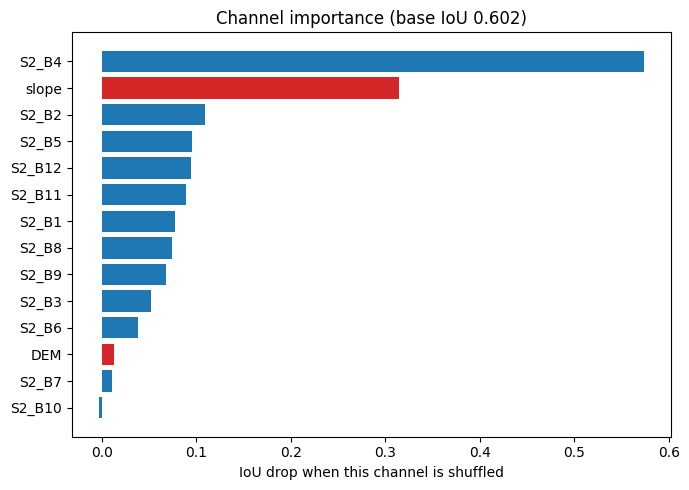

{'S2_B4': 0.5733, 'slope': 0.3141, 'S2_B2': 0.1093, 'S2_B5': 0.0953, 'S2_B12': 0.094, 'S2_B11': 0.0889, 'S2_B1': 0.0778, 'S2_B8': 0.0748, 'S2_B9': 0.0682, 'S2_B3': 0.0519, 'S2_B6': 0.0382, 'DEM': 0.013, 'S2_B7': 0.0108, 'S2_B10': -0.0031}


In [ ]:
def iou_on_array(raw):
    tp = fp = fn = 0.0
    for s in range(0, len(raw), 64):
        x = to_input(raw[s:s + 64]).to(device)
        p = predict_probs(x, False)[:, 0].cpu().numpy() > 0.5
        t = Yt[s:s + 64, 0] > 0.5
        tp += (p & t).sum(); fp += (p & ~t).sum(); fn += (~p & t).sum()
    return tp / (tp + fp + fn + 1e-9)

base_iou = iou_on_array(Xt_raw)
rng = np.random.RandomState(0)
drops = {}
for c in range(14):
    shuffled = Xt_raw.copy()
    shuffled[:, c] = Xt_raw[rng.permutation(len(Xt_raw)), c]
    drops[CHANNEL_NAMES[c]] = float(base_iou - iou_on_array(shuffled))

order = sorted(drops, key=drops.get)
plt.figure(figsize=(7, 5))
plt.barh(order, [drops[k] for k in order], color=['tab:red' if k in ('slope', 'DEM') else 'tab:blue' for k in order])
plt.xlabel("IoU drop when this channel is shuffled"); plt.title(f"Channel importance (base IoU {base_iou:.3f})")
plt.tight_layout(); plt.savefig(f'{OUT}/channel_importance.png', dpi=150); plt.show()
print({k: round(v, 4) for k, v in sorted(drops.items(), key=lambda kv: -kv[1])})

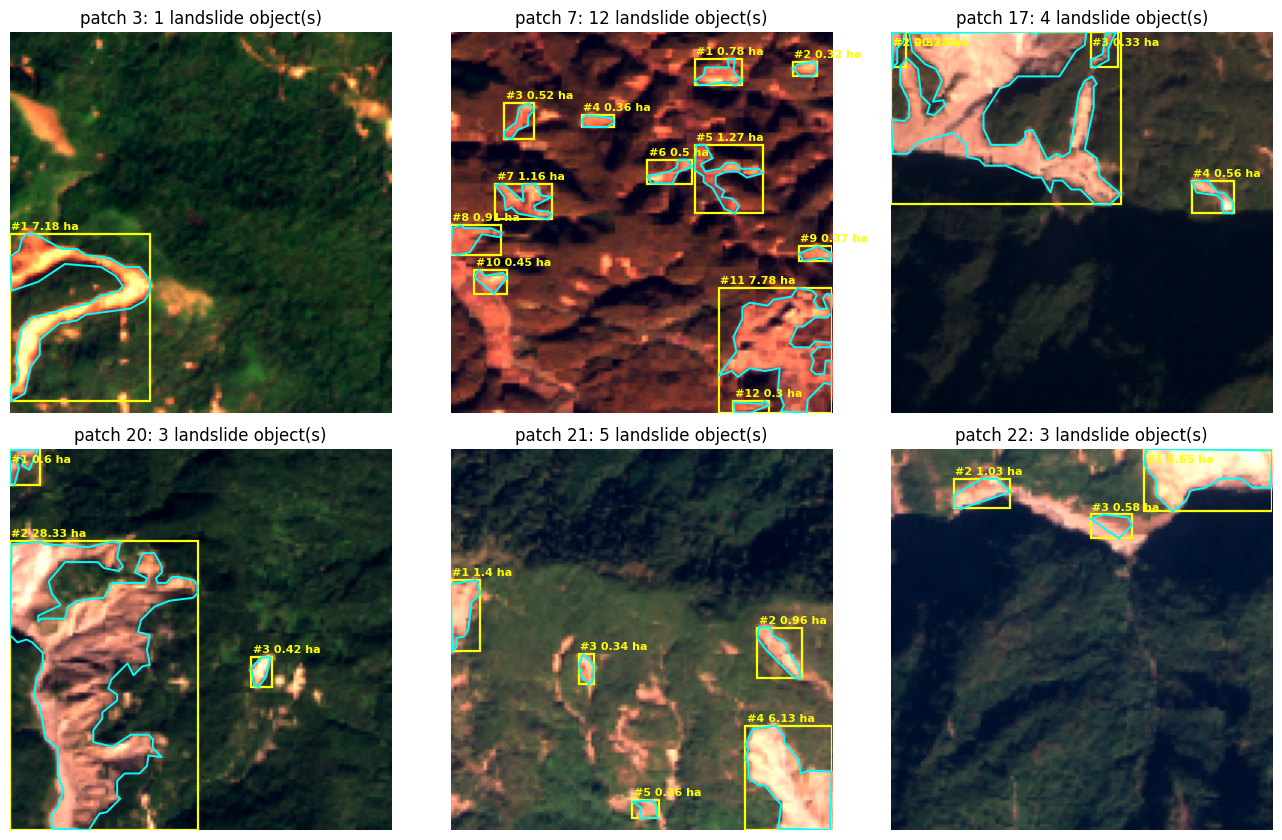

saved detected_landslides.json (boxes, polygons, areas)


In [ ]:
def extract_instances(prob, thr, min_pixels=30, px_area_ha=0.01):
    lab, n = ndi.label(prob > thr)
    out = []
    for k in range(1, n + 1):
        region = lab == k
        area = int(region.sum())
        if area < min_pixels:
            continue
        rows, cols = np.where(region)
        contours = measure.find_contours(np.pad(region.astype(np.uint8), 1), 0.5)
        outline = max(contours, key=len) - 1                     # undo the padding; (row, col)
        poly = measure.approximate_polygon(outline, tolerance=0.8)
        out.append({
            'id': len(out) + 1,
            'bbox_xyxy': [int(cols.min()), int(rows.min()), int(cols.max()), int(rows.max())],
            'area_px': area, 'area_ha': round(area * px_area_ha, 2),
            'mean_confidence': round(float(prob[region].mean()), 3),
            'polygon_xy': [[round(float(p[1]), 1), round(float(p[0]), 1)] for p in poly],
        })
    return out

def draw_instances(ax, instances):
    for d in instances:
        x0, y0, x1, y1 = d['bbox_xyxy']
        ax.add_patch(plt.Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0 + 1, y1 - y0 + 1, fill=False, edgecolor='yellow', linewidth=1.6))
        poly = np.array(d['polygon_xy'])
        ax.plot(poly[:, 0], poly[:, 1], color='cyan', linewidth=1.4)
        ax.text(x0, max(y0 - 2, 4), f"#{d['id']} {d['area_ha']} ha", color='yellow', fontsize=8, fontweight='bold')

all_found = {}
fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
for a, (r, i) in zip(ax.ravel(), enumerate(sel)):
    inst = extract_instances(probs[r], CH['thr'])
    all_found[f'test_patch_{i}'] = inst
    a.imshow(rgb_of(Xt_raw[i])); draw_instances(a, inst)
    a.set_title(f"patch {i}: {len(inst)} landslide object(s)"); a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/instances.png', dpi=150); plt.show()
json.dump(all_found, open(f'{OUT}/detected_landslides.json', 'w'), indent=1)
print("saved detected_landslides.json (boxes, polygons, areas)")

In [ ]:
import gradio as gr

def fig_to_img(fig):
    fig.canvas.draw()
    img = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    plt.close(fig)
    return img

def analyze(sample_idx, upload):
    try:
        if upload is not None:
            path = upload if isinstance(upload, str) else upload.name
            with h5py.File(path) as h:
                arr = np.nan_to_num(first(h)).astype(np.float32)
            if arr.shape != (128, 128, 14):
                return None, None, f"Expected a 128x128x14 patch, got shape {arr.shape}."
            raw, truth, title = arr.transpose(2, 0, 1), None, "uploaded patch"
        else:
            i = int(sample_idx)
            raw, truth, title = Xt_raw[i], Yt[i, 0] > 0.5, f"test patch #{i}"

        x = to_input(raw[None]).to(device)
        prob = predict_probs(x, CH['tta'])[0, 0].cpu().numpy()
        inst = extract_instances(prob, CH['thr'])
        cam = gradcam(x, CH['thr'])

        fig, ax = plt.subplots(1, 4, figsize=(17, 4.4))
        ax[0].imshow(rgb_of(raw)); draw_instances(ax[0], inst); ax[0].set_title(f"{title}: {len(inst)} landslide(s)")
        ax[1].imshow(prob, cmap='magma', vmin=0, vmax=1); ax[1].set_title("Landslide probability")
        ax[2].imshow(raw[12], cmap='terrain'); ax[2].set_title("Terrain slope (input channel)")
        if truth is not None:
            ax[3].imshow(err_map(prob > CH['thr'], truth)); ax[3].set_title("green ok / red false alarm / blue missed")
        else:
            ax[3].imshow(prob > CH['thr'], cmap='gray'); ax[3].set_title("Predicted mask")
        for a in ax: a.axis('off')
        plt.tight_layout(); overview = fig_to_img(fig)

        fig2, a2 = plt.subplots(1, 1, figsize=(4.6, 4.6))
        a2.imshow(rgb_of(raw)); a2.imshow(cam, cmap='jet', alpha=0.45, vmin=0, vmax=1)
        if truth is not None:
            a2.contour(truth.astype(float), [0.5], colors='white', linewidths=1.2)
        a2.set_title("Grad-CAM: where the model looked"); a2.axis('off')
        plt.tight_layout(); cam_img = fig_to_img(fig2)

        if inst:
            lines = [f"#{d['id']}: area {d['area_ha']} ha ({d['area_px']} px), confidence {d['mean_confidence']}, box {d['bbox_xyxy']}" for d in inst]
            summary = f"Model: {CH['label']} | threshold {CH['thr']} | TTA {CH['tta']}\n" + "\n".join(lines)
        else:
            summary = "No landslide detected in this patch."
        return overview, cam_img, summary
    except Exception as e:
        return None, None, f"Something went wrong: {type(e).__name__}: {e}"

with gr.Blocks(title="TerraSeg AI - Landslide Detection") as demo:
    gr.Markdown("# TerraSeg AI: landslide detection and boundary mapping\n"
                "Sentinel-2 optical bands + slope + elevation (14 channels) -> ResNet34 U-Net. "
                "Pick a held-out test patch, or upload a 128x128x14 `.h5` patch.")
    with gr.Row():
        idx = gr.Slider(0, len(Xt_raw) - 1, value=int(sel[0]), step=1, label="Test patch number")
        up = gr.File(label="(optional) upload a .h5 patch", file_types=[".h5"])
    btn = gr.Button("Detect landslides", variant="primary")
    out1 = gr.Image(label="Detection")
    out2 = gr.Image(label="Explanation (Grad-CAM)")
    out3 = gr.Textbox(label="Detected landslides", lines=8)
    btn.click(analyze, [idx, up], [out1, out2, out3])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2cdeb3f609e034e077.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
big   = [i for i in range(len(Xt_raw)) if Yt[i].sum() >= 800][:5]
small = [i for i in range(len(Xt_raw)) if 50 <= Yt[i].sum() < 200][:3]
none  = [i for i in range(len(Xt_raw)) if Yt[i].sum() == 0][:3]
print("big landslide :", big)
print("small landslide:", small)
print("no landslide   :", none)
print("default demo patch:", int(sel[0]))

big landslide : [7, 17, 20, 21, 28]
small landslide: [6, 14, 35]
no landslide   : [0, 1, 2]
default demo patch: 3


In [ ]:
from google.colab import files
i = int(sel[0])
path = img_files[test_idx[i]]
print(path)
files.download(path)

/content/l4s/images/train/image_3600.h5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
cands = {'encoder.layer3': model.encoder.layer3[-1], 'encoder.layer4': model.encoder.layer4[-1]}
for n in (2, 3):
    try: cands[f'decoder.block{n}'] = model.decoder.blocks[n]
    except Exception as e: print('skip decoder block', n, e)

idxs = [i for i in range(len(Xt_raw)) if Yt[i].sum() >= 300][:60]
rows = []
for name, layer in cands.items():
    g = GradCAM(model, layer)
    enrich, empty = [], 0
    for i in idxs:
        cam = g(to_input(Xt_raw[i:i+1]).to(device), CH['thr'])
        gt = Yt[i, 0] > 0.5
        if cam.sum() == 0:
            empty += 1; continue
        enrich.append((cam[gt].sum() / cam.sum()) / gt.mean())
    rows.append({'layer': name, 'empty maps': f'{empty}/{len(idxs)}',
                 'enrichment (1 = chance, higher = better)': round(float(np.mean(enrich)), 2) if enrich else None})
display(pd.DataFrame(rows))

,layer,empty maps,"enrichment (1 = chance, higher = better)"
0,encoder.layer3,34/60,3.48
1,encoder.layer4,33/60,1.75
2,decoder.block2,0/60,1.44
3,decoder.block3,0/60,4.27


In [ ]:
BEST = 'decoder.block3'     # <- replace with your winner from the table
gradcam = GradCAM(model, cands[BEST])

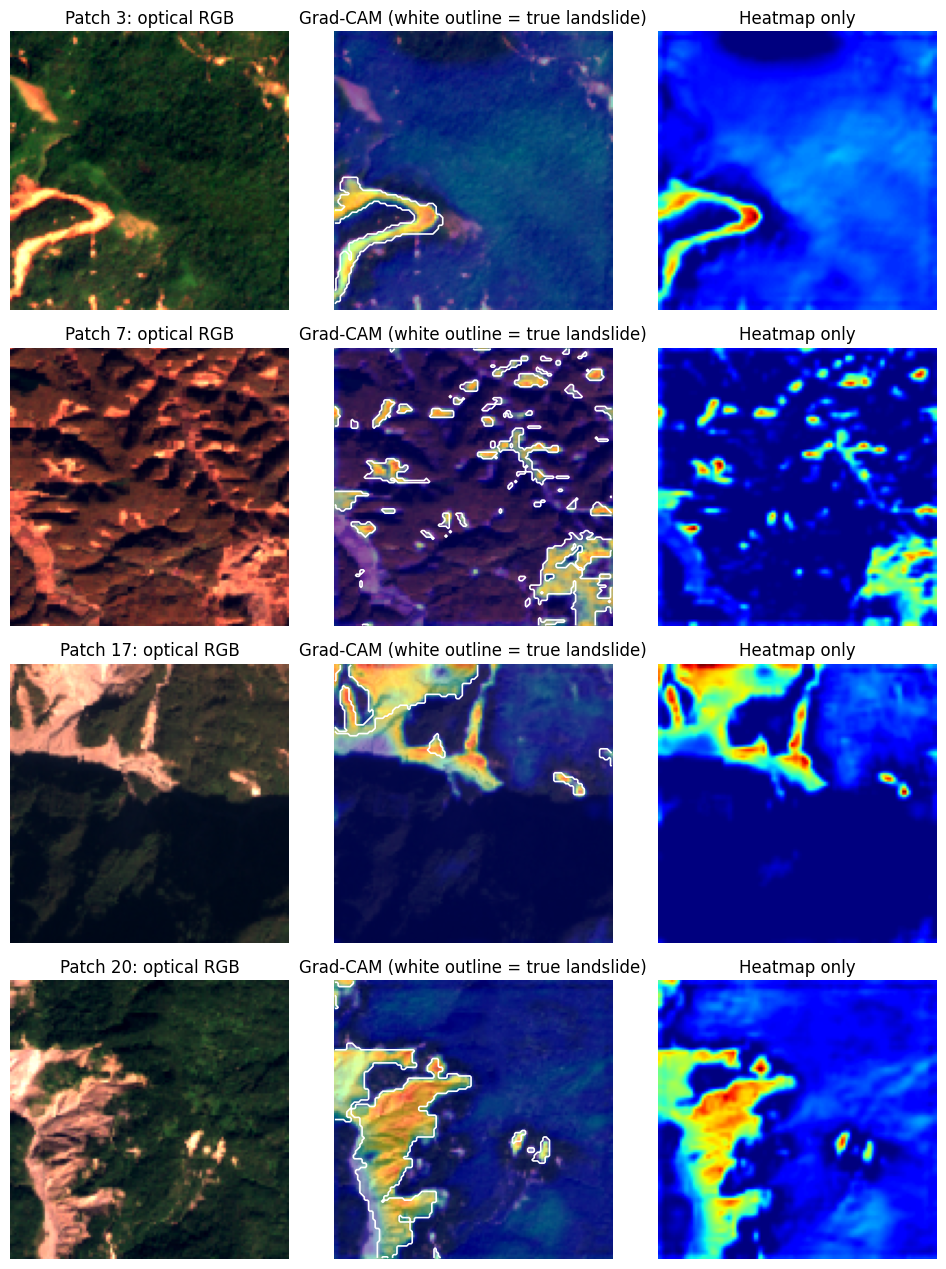

In [ ]:
fig, ax = plt.subplots(4, 3, figsize=(10, 12.8))
for r, i in enumerate(sel[:4]):
    x = to_input(Xt_raw[i:i + 1]).to(device)
    cam = gradcam(x, CH['thr'])
    ax[r, 0].imshow(rgb_of(Xt_raw[i])); ax[r, 0].set_title(f"Patch {i}: optical RGB")
    ax[r, 1].imshow(rgb_of(Xt_raw[i])); ax[r, 1].imshow(cam, cmap='jet', alpha=0.45, vmin=0, vmax=1)
    ax[r, 1].contour(Yt[i, 0], [0.5], colors='white', linewidths=1.2); ax[r, 1].set_title("Grad-CAM (white outline = true landslide)")
    ax[r, 2].imshow(cam, cmap='jet', vmin=0, vmax=1); ax[r, 2].set_title("Heatmap only")
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/gradcam_fixed.png', dpi=150); plt.show()

In [ ]:
none  = [i for i in range(len(Xt_raw)) if Yt[i].sum() == 0][:3]
small = [i for i in range(len(Xt_raw)) if 0 < Yt[i].sum() < 150][:3]
print("no-landslide patches:", none)
print("tiny-landslide patches:", small)

no-landslide patches: [0, 1, 2]
tiny-landslide patches: [10, 14, 30]
